# IND320 – Part 3

## 1. Open-Meteo API

**AI use:** Codex assisted with the API example, region boundaries, point sampling, weather downloads, and the SPC, LOF, STL and spectrogram analyses, and the Streamlit weather controls.

### Data types

[Open-Meteo](https://open-meteo.com/en/docs) has several subsections:

- **Weather Forecast:** weather forecasts.
- **Historical Weather:** historical weather based on reanalysis.
- **Historical Forecast:** archived forecasts.

We use [Historical Weather](https://open-meteo.com/en/docs/historical-weather-api) with the **ERA5** model.

### Selecting data and generating Python code

The website lets us select coordinates, dates, hourly or daily values, weather variables and a model. **API Response → Python** generates code from these selections.

The example below retrieves hourly temperature and precipitation for Trondheim, 1–7 January 2024, using `requests`.

In [1]:
import requests
import pandas as pd

# The historical endpoint retrieves reanalysis data.
url = "https://archive-api.open-meteo.com/v1/archive"
params = {
    "latitude": 63.43,
    "longitude": 10.40,
    "start_date": "2024-01-01",
    "end_date": "2024-01-07",
    "hourly": "temperature_2m,precipitation",
    "models": "era5",
    "timezone": "GMT",
}

# Retrieve one week for one location. Raise an error if the request fails.
response = requests.get(url, params=params, timeout=30)
response.raise_for_status()
weather = response.json()
print("HTTP status:", response.status_code)
print("API request:", response.url)

HTTP status: 200
API request: https://archive-api.open-meteo.com/v1/archive?latitude=63.43&longitude=10.4&start_date=2024-01-01&end_date=2024-01-07&hourly=temperature_2m%2Cprecipitation&models=era5&timezone=GMT


### API response

The response is converted to a table with UTC timestamps.

In [2]:
# Convert the hourly values to a table and interpret timestamps as UTC.
weather_df = pd.DataFrame(weather["hourly"])
weather_df["time"] = pd.to_datetime(weather_df["time"], utc=True)
weather_df = weather_df.set_index("time")

# Run the checks needed for this connection test.
expected_times = pd.date_range("2024-01-01", periods=168, freq="h", tz="UTC")
assert weather_df.index.equals(expected_times), "Unexpected timestamps."
assert not weather_df.isna().any().any(), "The API response contains missing weather values."
assert weather["hourly_units"]["temperature_2m"] == "°C"
assert weather["hourly_units"]["precipitation"] == "mm"

print("Number of hours:", len(weather_df))
print("Units:", weather["hourly_units"])
print("Model grid coordinates:", weather["latitude"], weather["longitude"])
weather_df.head()

Number of hours: 168
Units: {'time': 'iso8601', 'temperature_2m': '°C', 'precipitation': 'mm'}
Model grid coordinates: 63.5 10.5


,temperature_2m,precipitation
time,,
2024-01-01 00:00:00+00:00,-2.7,0.0
2024-01-01 01:00:00+00:00,-2.7,0.0
2024-01-01 02:00:00+00:00,-2.5,0.0
2024-01-01 03:00:00+00:00,-2.3,0.0
2024-01-01 04:00:00+00:00,-2.3,0.0


## 2. Region boundaries and random weather locations

In [NVE Atlas](https://atlas.nve.no), **Budområder** (API name: Budomraade) is under Nettanlegg → Nettområder, and **NVE_Region** is under Administrasjon → Administrative områder. We retrieve these layers from NVE's REST services and save them as shapefiles.

The assignment's precipitation regions are grouped as **East (Øst) = RS + RØ**, **West (Vest) = RV**, and **North (Nord) = RM + RN**. These are groups of NVE regions, rather than detailed hydrological catchments.

In [2]:
from pathlib import Path
import requests
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

# Support opening the notebook from the project or notebooks directory.
project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent
geo_dir = project_root / "data" / "geography"
geo_dir.mkdir(parents=True, exist_ok=True)

# Atlas layer sources. The Norway layer restricts sampling to land.
sources = {
    "budomraader": ("https://kart.nve.no/enterprise/rest/services/Nettomraader/MapServer/0", "budomr"),
    "nve_regioner": ("https://kart.nve.no/enterprise/rest/services/Mapservices/Administrasjon2/MapServer/0", "REGION"),
    "norge_land": ("https://kart.nve.no/enterprise/rest/services/Mapservices/Administrasjon2/MapServer/11", "OBJECTID"),
}

# Download once. Subsequent runs read the saved shapefiles.
for name, (layer_url, fields) in sources.items():
    shape_path = geo_dir / f"{name}.shp"
    if not shape_path.exists():
        response = requests.get(layer_url + "/query", params={
            "where": "1=1", "outFields": fields, "returnGeometry": "true",
            "outSR": 25833, "f": "geojson",
        }, timeout=60)
        response.raise_for_status()
        data = response.json()
        assert "features" in data, data.get("error", "No map features in the response.")
        assert not data.get("exceededTransferLimit", False), "Incomplete map layer."
        layer = gpd.GeoDataFrame.from_features(data["features"], crs="EPSG:25833")
        layer.to_file(shape_path, driver="ESRI Shapefile", encoding="UTF-8")

elspot = gpd.read_file(geo_dir / "budomraader.shp")
nve_regions = gpd.read_file(geo_dir / "nve_regioner.shp")
land = gpd.read_file(geo_dir / "norge_land.shp")
print("Electricity price areas:", elspot["budomr"].tolist())
print("NVE regions:", nve_regions["REGION"].tolist())

Electricity price areas: ['NO 1', 'NO 2', 'NO 3', 'NO 4', 'NO 5']
NVE regions: ['RV', 'RM', 'RN', 'RØ', 'RS']


### 2.1 Combine the regions

Regions are combined **before** sampling, so East and North each receive 1000 points. The layers include sea areas; sampling is restricted to land using the Norge_N5000 layer in Atlas. We use an equal-area coordinate system (EPSG:3035) for sampling.

In [3]:
# Keep NO1–NO5 as separate regions.
elspot["region"] = elspot["budomr"].str.replace(" ", "", regex=False)
assert set(elspot["region"]) == {"NO1", "NO2", "NO3", "NO4", "NO5"}
assert set(nve_regions["REGION"]) == {"RS", "RØ", "RV", "RM", "RN"}

# Combine regions as specified in the assignment.
region_groups = {"RS": "Øst", "RØ": "Øst", "RV": "Vest", "RM": "Nord", "RN": "Nord"}
nve_regions["region"] = nve_regions["REGION"].map(region_groups)
precipitation_regions = nve_regions[["region", "geometry"]].dissolve(by="region", as_index=False)

regions = gpd.GeoDataFrame(pd.concat([
    elspot[["region", "geometry"]], precipitation_regions,
], ignore_index=True), crs=elspot.crs).to_crs(3035)
regions = regions.sort_values("region").reset_index(drop=True)

# Exclude sea areas before sampling. Preserve the source shapefiles.
land_geometry = land.to_crs(regions.crs).geometry.union_all()
regions["geometry"] = regions.geometry.intersection(land_geometry)
assert regions.geometry.is_valid.all() and not regions.geometry.is_empty.any()
regions[["region"]]

,region
0,NO1
1,NO2
2,NO3
3,NO4
4,NO5
5,Nord
6,Vest
7,Øst


### 2.2 Sample and save 1000 points per region

Points are sampled randomly and uniformly over the area. A fixed seed (`42`) makes the sample reproducible. Longitude and latitude are saved in WGS84 for later weather downloads.

In [4]:
# sample_points also distributes points among islands according to their area.
points = gpd.GeoDataFrame(
    regions[["region"]],
    geometry=regions.geometry.sample_points(size=1000, rng=42),
    crs=regions.crs,
).explode(index_parts=False).reset_index(drop=True)
points["point_id"] = points.groupby("region").cumcount() + 1

# Check the count and that each point lies within its assigned region.
assert points.groupby("region").size().eq(1000).all()
for region, group in points.groupby("region"):
    boundary = regions.loc[regions["region"].eq(region), "geometry"].iloc[0]
    assert group.geometry.within(boundary).all()

coordinates = points.to_crs(4326)
coordinates["longitude"] = coordinates.geometry.x
coordinates["latitude"] = coordinates.geometry.y
coordinates[["region", "point_id", "longitude", "latitude"]].to_csv(
    geo_dir / "weather_locations.csv", index=False,
)
print("Coordinates saved to data/geography/weather_locations.csv")
points.groupby("region").size().rename("number_of_locations").to_frame()

Coordinates saved to data/geography/weather_locations.csv


,number_of_locations
region,
NO1,1000
NO2,1000
NO3,1000
NO4,1000
NO5,1000
Nord,1000
Vest,1000
Øst,1000


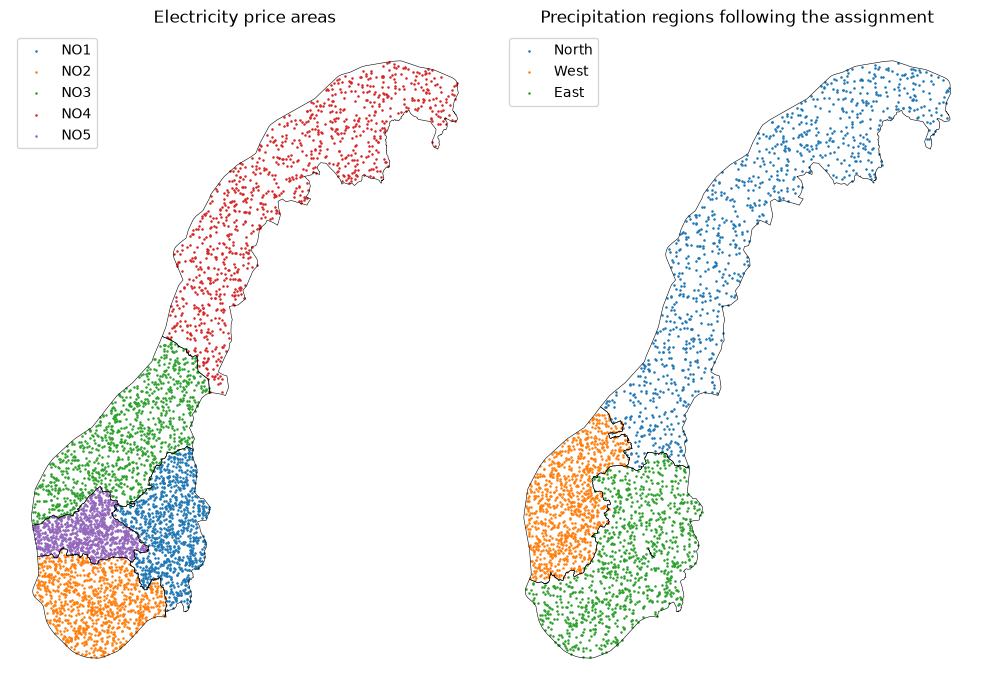

In [5]:
# Use two maps to inspect the overlapping region classifications separately.
fig, axes = plt.subplots(1, 2, figsize=(10, 7))
for ax, labels, title in [
    (axes[0], ["NO1", "NO2", "NO3", "NO4", "NO5"], "Electricity price areas"),
    (axes[1], ["Øst", "Vest", "Nord"], "Precipitation regions following the assignment"),
]:
    regions.loc[regions["region"].isin(labels)].boundary.plot(ax=ax, color="black", linewidth=0.4)
    points.loc[points["region"].isin(labels)].plot(
        ax=ax, column="region", categorical=True, legend=True, markersize=0.7,
    )
    region_names = {"Øst": "East", "Vest": "West", "Nord": "North"}
    for label in ax.get_legend().get_texts():
        label.set_text(region_names.get(label.get_text(), label.get_text()))
    ax.set_title(title)
    ax.set_axis_off()
plt.tight_layout()
plt.show()

## 3. Download ERA5 weather data for a region

The function takes a region and date interval, looks up its coordinates, and retrieves hourly temperature (°C) and precipitation (mm) from [Open-Meteo's Historical Weather API](https://open-meteo.com/en/docs/historical-weather-api), using **ERA5** and **UTC**.

The API rejected the request for all 1000 points as too large. We therefore use batches of 100. Each batch and the combined result are saved under `no_sync/weather/` for reuse.

The notebook and Streamlit share the download function in `dashboard/weather_data.py`. The app uses hourly regional means and starts new downloads only after a button press.

In [ ]:
from pathlib import Path
import sys

# Share the download function with the Streamlit weather page.
root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
from dashboard.weather_data import download_weather


In [7]:
# 2024 is a leap year: 366 days × 24 hours = 8784 hours per location.
weather_no3 = download_weather("NO3", "2024-01-01", "2024-12-31")
assert weather_no3["point_id"].nunique() == 1000
assert weather_no3.groupby("point_id").size().eq(8784).all()
assert not weather_no3.duplicated(["point_id", "time"]).any()
assert not weather_no3.isna().any().any()
print("Number of locations:", weather_no3["point_id"].nunique())
print("Hours per location:", 8784)
print("Number of rows:", len(weather_no3))
weather_no3.head()

Reading saved data: NO3_era5_2024-01-01_2024-12-31.csv.gz


Number of locations: 1000
Hours per location: 8784
Number of rows: 8784000


,point_id,time,temperature_2m,precipitation
0,1,2024-01-01 00:00:00+00:00,-7.3,0.0
1,1,2024-01-01 01:00:00+00:00,-7.6,0.0
2,1,2024-01-01 02:00:00+00:00,-7.8,0.0
3,1,2024-01-01 03:00:00+00:00,-7.9,0.0
4,1,2024-01-01 04:00:00+00:00,-7.8,0.0


## 4. Precipitation outliers: DCT and SPC

We calculate average precipitation across NO3's 1000 points for each hour of 2024. The assignment's term “SATV” is interpreted here as seasonally adjusted **precipitation deviations**.

In [8]:
# Count valid values while calculating the mean.
hourly_precipitation = weather_no3.groupby("time")["precipitation"].agg(["mean", "count"]).sort_index()
assert len(hourly_precipitation) == 8784
assert hourly_precipitation["count"].eq(1000).all()
precipitation_no3 = hourly_precipitation["mean"].rename("precipitation_mm")
print("Hourly averages:", len(precipitation_no3), "hours with 1000 locations each.")

Hourly averages: 8784 hours with 1000 locations each.


### 4.1 Analysis function

The DCT high-pass filter removes frequencies below `cutoff_frequency`, expressed in **cycles per day**. The default `1/30` removes variations with periods longer than approximately 30 days.

The median and scaled MAD are calculated from deviations for the **entire year**. The limits on the original precipitation scale are:

**slow variation + median(deviations) ± n_std × robust standard deviation**

The default is `n_std=3`. The plot shows precipitation, limits and outliers; the deviations are used only in the calculation. Sources: [DCT](https://docs.scipy.org/doc/scipy/reference/generated/scipy.fft.dct.html) and [scaled MAD](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.median_abs_deviation.html).

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.fft import dct, idct
from scipy.stats import median_abs_deviation


def plot_precipitation_spc(precipitation, cutoff_frequency=1/30, n_std=3):
    """Return a figure, summary and outlier table for an hourly precipitation series."""
    series = precipitation.sort_index()
    if not isinstance(series.index, pd.DatetimeIndex) or len(series) < 3:
        raise ValueError("Use a time series with at least three hourly observations.")
    if not (series.index[1:] - series.index[:-1] == pd.Timedelta(hours=1)).all():
        raise ValueError("The series must have consecutive, unique hours.")
    values = series.to_numpy(dtype=float)
    if not np.isfinite(values).all():
        raise ValueError("The series contains missing or invalid values.")
    if not np.isfinite(cutoff_frequency) or not 0 < cutoff_frequency < 12:
        raise ValueError("The cutoff frequency must be between 0 and 12 cycles per day.")
    if not np.isfinite(n_std) or n_std <= 0:
        raise ValueError("The number of standard deviations must be positive.")

    # DCT-II has frequency k / (2*N*dt), with dt = 1/24 day.
    coefficients = dct(values, type=2, norm="ortho")
    frequencies = np.arange(len(values)) / (2 * len(values) / 24)
    coefficients[frequencies < cutoff_frequency] = 0
    deviations = idct(coefficients, type=2, norm="ortho")
    slow_variation = values - deviations

    # scale="normal" gives MAD × 1.4826 as a robust estimate of the standard deviation.
    median_deviation = np.median(deviations)
    robust_sigma = median_abs_deviation(deviations, scale="normal")
    center = slow_variation + median_deviation
    lower = center - n_std * robust_sigma
    upper = center + n_std * robust_sigma
    outlier_mask = (values < lower) | (values > upper)

    # Plot the original precipitation and control limits, without the filtered deviations.
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(series.index, values, color="tab:blue", linewidth=0.7, label="Average precipitation")
    ax.plot(series.index, lower, color="darkorange", linestyle="--", linewidth=0.9, label="Lower SPC limit")
    ax.plot(series.index, upper, color="darkorange", linestyle="--", linewidth=0.9, label="Upper SPC limit")
    ax.scatter(series.index[outlier_mask], values[outlier_mask],
               color="crimson", s=12, zorder=3, label="Outliers")
    ax.set(title="Outliers in average precipitation – DCT/SPC",
           xlabel="Time (UTC)", ylabel="Precipitation per hour (mm)")
    ax.legend(loc="upper left", ncol=2)
    ax.grid(alpha=0.2)
    fig.tight_layout()

    summary = {
        "number_of_hours": len(values),
        "number_of_outliers": int(outlier_mask.sum()),
        "percentage": 100 * outlier_mask.mean(),
        "robust_standard_deviation_mm": float(robust_sigma),
    }
    outliers = pd.DataFrame({
        "precipitation_mm": values, "lower_limit_mm": lower, "upper_limit_mm": upper,
    }, index=series.index).loc[outlier_mask]
    return fig, summary, outliers

### 4.2 Test the function

We use a signal with known slow variation and faster oscillations. We then add a clear spike and check that it is flagged.

In [10]:
# The cosines follow the DCT basis, giving a known slow component.
n = 24 * 120
x = np.pi * (np.arange(n) + 0.5) / n
slow = 3 + 0.6 * np.cos(2 * x)
synthetic = pd.Series(slow + 0.1 * np.cos(100 * x),
                      index=pd.date_range("2024-01-01", periods=n, freq="h", tz="UTC"))
test_fig, test_summary, _ = plot_precipitation_spc(synthetic)
# The midpoint of the limits should follow the known slow variation.
lines = test_fig.axes[0].lines
estimated_center = (lines[1].get_ydata() + lines[2].get_ydata()) / 2
assert np.allclose(estimated_center, slow, atol=1e-10)
assert test_summary["number_of_outliers"] == 0
plt.close(test_fig)

spike_time = synthetic.index[n // 2]
synthetic.loc[spike_time] += 5
test_fig, _, test_outliers = plot_precipitation_spc(synthetic)
assert spike_time in test_outliers.index
plt.close(test_fig)

# A lower cutoff allows the slow cosine to enter the deviations.
clean = synthetic.copy()
clean.loc[spike_time] -= 5
test_fig, _, _ = plot_precipitation_spc(clean, cutoff_frequency=1/200)
changed_lines = test_fig.axes[0].lines
changed_center = (changed_lines[1].get_ydata() + changed_lines[2].get_ydata()) / 2
assert not np.allclose(changed_center, slow, atol=1e-4)
plt.close(test_fig)
# A moderate spike should be flagged at three standard deviations, but not four.
moderate = clean.copy()
moderate.loc[spike_time] += 0.26
for k, expected in [(3, True), (4, False)]:
    test_fig, _, test_outliers = plot_precipitation_spc(moderate, n_std=k)
    assert (spike_time in test_outliers.index) == expected
    plt.close(test_fig)
print("Tests passed: filtering, injected spike and both parameters.")

Tests passed: filtering, injected spike and both parameters.


### 4.3 NO3 in 2024

We use the defaults: a 30-day cutoff period and three robust standard deviations. Outliers are statistically unusual hours under this method, rather than necessarily data errors. The lower control limit may be negative because it is a statistical limit.

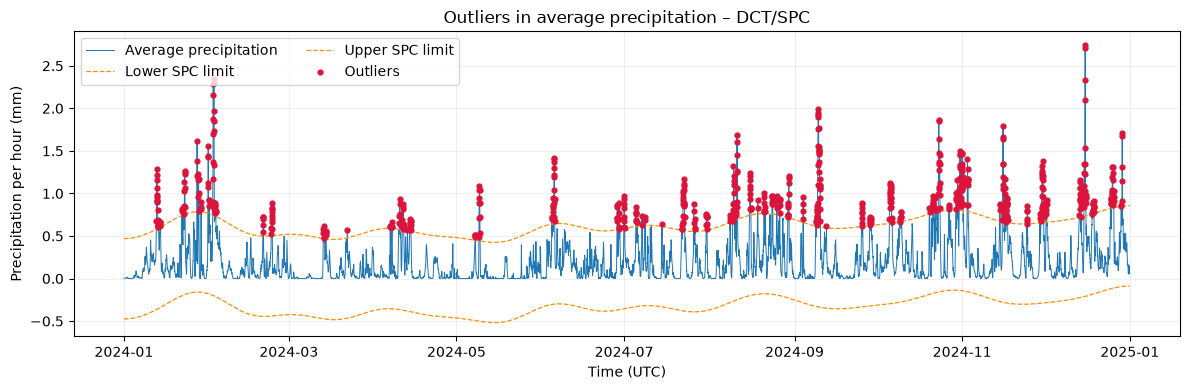

,number_of_hours,number_of_outliers,percentage,robust_standard_deviation_mm
0,8784,638,7.263,0.157


In [11]:
# Use all hours of 2024 for both filtering and robust estimation.
spc_fig, spc_summary, precipitation_outliers = plot_precipitation_spc(precipitation_no3)
plt.show()
pd.DataFrame([spc_summary]).round(3)

In [12]:
# The ten outlier hours with the highest precipitation.
precipitation_outliers.nlargest(10, "precipitation_mm").round(3)

,precipitation_mm,lower_limit_mm,upper_limit_mm
time,,,
2024-12-15 18:00:00+00:00,2.742,-0.209,0.735
2024-12-15 17:00:00+00:00,2.705,-0.209,0.734
2024-02-02 18:00:00+00:00,2.346,-0.203,0.741
2024-12-15 19:00:00+00:00,2.328,-0.208,0.735
2024-02-02 17:00:00+00:00,2.300,-0.203,0.741
2024-02-02 12:00:00+00:00,2.291,-0.200,0.744
2024-02-02 13:00:00+00:00,2.162,-0.200,0.743
2024-12-15 16:00:00+00:00,2.096,-0.210,0.734
2024-09-09 15:00:00+00:00,1.990,-0.334,0.610


## 5. Temperature anomalies: Local Outlier Factor

We calculate average temperature across NO3's 1000 points for each hour of 2024. LOF compares the density around observations with the density around their neighbours.

In [13]:
# Each hour must include all 1000 locations.
hourly_temperature = weather_no3.groupby("time")["temperature_2m"].agg(["mean", "count"]).sort_index()
assert len(hourly_temperature) == 8784
assert hourly_temperature["count"].eq(1000).all()
temperature_no3 = hourly_temperature["mean"].rename("temperature_c")
print("Hourly averages:", len(temperature_no3), "hours with 1000 locations each.")

Hourly averages: 8784 hours with 1000 locations each.


### 5.1 Analysis function

We use **temperature and an hourly time index** as inputs. Both are standardised so that the scale of the time axis does not dominate the distances. The model uses 20 neighbours.

`outlier_fraction` is adjustable, with **0.01 (1%)** as the default. This proportion sets the anomaly threshold; flagged observations do not prove that the weather data are incorrect. A higher LOF score indicates a more unusual observation. Sources: [LOF](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.LocalOutlierFactor.html) and [standardisation](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html).

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler


def plot_temperature_lof(temperature, outlier_fraction=0.01):
    """Return a figure, summary and anomaly table for an hourly temperature series."""
    series = temperature.sort_index()
    if not isinstance(series.index, pd.DatetimeIndex) or len(series) < 21:
        raise ValueError("LOF with 20 neighbours requires at least 21 hourly observations.")
    if not (series.index[1:] - series.index[:-1] == pd.Timedelta(hours=1)).all():
        raise ValueError("The series must have consecutive, unique hours.")
    values = series.to_numpy(dtype=float)
    if not np.isfinite(values).all():
        raise ValueError("The series contains missing or invalid values.")
    if not np.isfinite(outlier_fraction) or not 0 < outlier_fraction <= 0.5:
        raise ValueError("The anomaly proportion must be greater than 0 and at most 0.5.")

    # Include time and give time and temperature equal standard deviations when calculating distances.
    features = np.column_stack([np.arange(len(values)), values])
    features = StandardScaler().fit_transform(features)
    model = LocalOutlierFactor(n_neighbors=20, contamination=outlier_fraction)
    anomaly_mask = model.fit_predict(features) == -1
    lof_scores = -model.negative_outlier_factor_

    # Plot temperature in °C, with classified anomalies in red.
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(series.index, values, color="tab:blue", linewidth=0.7,
            label="Average temperature")
    ax.scatter(series.index[anomaly_mask], values[anomaly_mask],
               color="crimson", s=18, zorder=3, label="Anomalies")
    ax.set(title=f"Anomalies in average temperature – LOF ({100 * outlier_fraction:g} %)",
           xlabel="Time (UTC)", ylabel="Temperature (°C)")
    ax.legend(loc="upper left")
    ax.grid(alpha=0.2)
    fig.tight_layout()

    summary = {
        "number_of_hours": len(values),
        "number_of_anomalies": int(anomaly_mask.sum()),
        "percentage": 100 * anomaly_mask.mean(),
        "selected_percentage": 100 * outlier_fraction,
    }
    anomalies = pd.DataFrame({
        "temperature_c": values, "lof_score": lof_scores,
    }, index=series.index).loc[anomaly_mask].sort_values("lof_score", ascending=False)
    return fig, summary, anomalies

### 5.2 Test the function

We add a clear warm and cold spike to a simple signal. We check that both are flagged, that the proportion can be changed, and that the result does not depend on whether temperatures are expressed in Celsius or Fahrenheit.

In [15]:
# Reproducible test signal with two known anomalies.
rng = np.random.default_rng(42)
n = 24 * 30
synthetic_temperature = pd.Series(
    10 + np.sin(2 * np.pi * np.arange(n) / (24 * 7)) + rng.normal(0, 0.05, n),
    index=pd.date_range("2024-01-01", periods=n, freq="h", tz="UTC"),
)
hot_time, cold_time = synthetic_temperature.index[[200, 500]]
synthetic_temperature.loc[hot_time] += 8
synthetic_temperature.loc[cold_time] -= 8

test_fig, test_summary, test_anomalies = plot_temperature_lof(synthetic_temperature)
assert hot_time in test_anomalies.index and cold_time in test_anomalies.index
assert test_summary["number_of_anomalies"] == 8  # 1% of 720 hours, rounded up.
plt.close(test_fig)

test_fig, larger_summary, _ = plot_temperature_lof(synthetic_temperature, outlier_fraction=0.05)
assert larger_summary["number_of_anomalies"] == 36
plt.close(test_fig)

# Standardisation should make the result independent of the temperature scale.
test_fig, _, fahrenheit_anomalies = plot_temperature_lof(synthetic_temperature * 1.8 + 32)
assert set(test_anomalies.index) == set(fahrenheit_anomalies.index)
plt.close(test_fig)
print("Tests passed: injected anomalies, adjusted proportion and temperature scale.")

Tests passed: injected anomalies, adjusted proportion and temperature scale.


### 5.3 NO3 in 2024

We use the default proportion of 1% and show the ten flagged hours with the highest LOF scores.

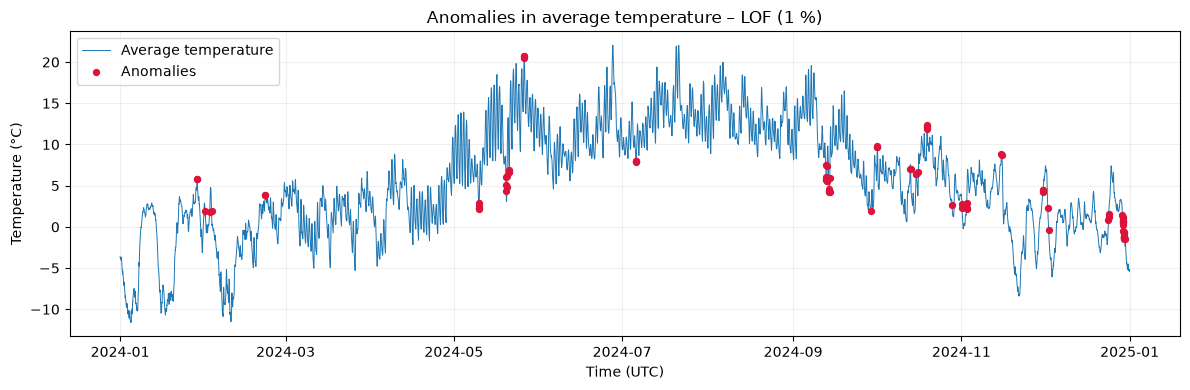

,number_of_hours,number_of_anomalies,percentage,selected_percentage
0,8784,88,1.002,1.0


In [16]:
# Apply the function to the average temperature series for all of 2024.
lof_fig, lof_summary, temperature_anomalies = plot_temperature_lof(temperature_no3)
plt.show()
pd.DataFrame([lof_summary]).round(3)

In [17]:
# Anomalies are ranked by LOF score, with the most unusual hours first.
temperature_anomalies.head(10).round(3)

,temperature_c,lof_score
time,,
2024-10-19 13:00:00+00:00,12.329,2.636
2024-10-19 14:00:00+00:00,12.236,2.486
2024-12-29 20:00:00+00:00,-0.733,2.483
2024-12-29 21:00:00+00:00,-0.978,2.476
2024-12-29 19:00:00+00:00,-0.673,2.390
2024-05-19 20:00:00+00:00,6.032,2.385
2024-05-20 06:00:00+00:00,6.229,2.362
2024-10-19 12:00:00+00:00,12.105,2.282
2024-05-10 03:00:00+00:00,2.142,2.244


## 6. Reservoir filling: STL decomposition

We use weekly filling fractions for **NO3 (EL area 3), 2015–2025**, from [NVE Magasinstatistikk](https://biapi.nve.no/magasinstatistikk/swagger/index.html). A multi-year series allows us to estimate an annual seasonal pattern. A period of **52 weekly observations** approximates one year.

In [1]:
from pathlib import Path
import pandas as pd
import requests

root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
nve_cache = root / "no_sync/nve_cache/reservoir_history.json"
# Reuse the NVE history saved earlier in the project. Download it if unavailable.
if nve_cache.exists():
    reservoir_history = pd.read_json(nve_cache)
else:
    response = requests.get(
        "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOffentligData",
        timeout=60,
    )
    response.raise_for_status()
    reservoir_history = pd.DataFrame(response.json())

reservoir_history["observation_date"] = pd.to_datetime(reservoir_history["dato_Id"])
# NO3 in the electricity-area map corresponds to EL area number 3 in Magasinstatistikk.
filling_no3 = (
    reservoir_history.loc[reservoir_history["omrType"].eq("EL") & reservoir_history["omrnr"].eq(3)]
    .set_index("observation_date")["fyllingsgrad"].sort_index().loc["2015":"2025"].rename("NO3")
)
print(f"NO3: {len(filling_no3)} weekly observations, "
      f"{filling_no3.index.min():%Y-%m-%d} to {filling_no3.index.max():%Y-%m-%d}.")

NO3: 574 weekly observations, 2015-01-04 to 2025-12-28.


### 6.1 Analysis function

STL separates the series into **trend + seasonal component + residual**. The adjustable defaults are:

- `seasonal=13`: smooths changes in the annual seasonal pattern across years.
- `trend=89`: smooths the trend over 89 weekly observations.
- `robust=True`: reduces the influence of unusual observations during fitting.

Both smoother lengths must be odd. The function returns a four-panel figure. Filling and trend are shown as percentages; seasonal and residual components are in percentage points (pp). Source: [statsmodels STL](https://www.statsmodels.org/stable/generated/statsmodels.tsa.seasonal.STL.html).

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import STL


def plot_reservoir_stl(filling_fraction, seasonal=13, trend=89, robust=True):
    """Return an STL decomposition figure for a regular weekly filling-fraction series."""
    series = filling_fraction.sort_index()
    if not isinstance(series.index, pd.DatetimeIndex) or len(series) < 104:
        raise ValueError("Use at least two 52-week cycles with a datetime index.")
    if not (series.index[1:] - series.index[:-1] == pd.Timedelta(days=7)).all():
        raise ValueError("The series must have consecutive, unique weekly observations.")
    if not np.isfinite(series.to_numpy(dtype=float)).all():
        raise ValueError("The series contains missing or invalid values.")
    if not isinstance(seasonal, (int, np.integer)) or seasonal < 3 or seasonal % 2 == 0:
        raise ValueError("The seasonal smoother must be an odd integer of at least 3.")
    if not isinstance(trend, (int, np.integer)) or trend <= 52 or trend % 2 == 0:
        raise ValueError("The trend smoother must be an odd integer greater than 52.")
    if not isinstance(robust, (bool, np.bool_)):
        raise ValueError("robust must be True or False.")

    # Fit the additive model to filling fractions, using an approximately annual period.
    result = STL(series, period=52, seasonal=seasonal, trend=trend, robust=robust).fit()
    components = [series, result.trend, result.seasonal, result.resid]
    labels = ["Filling (%)", "Trend (%)", "Seasonal (pp)", "Residual (pp)"]
    fig, axes = plt.subplots(4, 1, figsize=(12, 8), sharex=True)
    for ax, component, label in zip(axes, components, labels):
        # Multiplying by 100 changes fractions to percentages or percentage points.
        ax.plot(series.index, component * 100, color="tab:blue", linewidth=0.9)
        ax.set_ylabel(label)
        ax.grid(alpha=0.2)
    axes[2].axhline(0, color="grey", linewidth=0.6)
    axes[3].axhline(0, color="grey", linewidth=0.6)
    axes[-1].set_xlabel("Observation date")
    fig.suptitle(f"STL decomposition – {series.name or 'reservoir filling'}")
    fig.tight_layout(rect=(0, 0, 1, 0.97))
    return fig

### 6.2 Test the function

We use a weekly signal with a known trend and annual cycle, plus noise and one unusual observation. We check reconstruction, recovery of the seasonal pattern, and the effect of all three parameters.

In [3]:
# Six years of weekly data with a known trend and annual seasonal component.
rng = np.random.default_rng(42)
t = np.arange(6 * 52)
known_trend = 0.50 + 0.0002 * t
known_season = 0.15 * np.sin(2 * np.pi * t / 52)
synthetic_filling = pd.Series(
    known_trend + known_season + rng.normal(0, 0.005, len(t)),
    index=pd.date_range("2018-01-07", periods=len(t), freq="W-SUN"), name="Test signal",
)
spike = len(t) // 2 + 26
synthetic_filling.iloc[spike] += 0.30

test_fig = plot_reservoir_stl(synthetic_filling)
parts = [ax.lines[0].get_ydata() / 100 for ax in test_fig.axes]
assert np.allclose(parts[0], parts[1] + parts[2] + parts[3])
assert np.corrcoef(parts[2], known_season)[0, 1] > 0.99
plt.close(test_fig)

# Robust fitting should reduce the spike's influence on the estimated trend.
test_fig = plot_reservoir_stl(synthetic_filling, robust=False)
ordinary_trend = test_fig.axes[1].lines[0].get_ydata() / 100
assert abs(parts[1][spike] - known_trend[spike]) < abs(ordinary_trend[spike] - known_trend[spike])
plt.close(test_fig)

# Change each smoother independently and check that its fitted component changes.
for settings, axis in [({"seasonal": 7}, 2), ({"trend": 121}, 1)]:
    test_fig = plot_reservoir_stl(synthetic_filling, **settings)
    changed_component = test_fig.axes[axis].lines[0].get_ydata() / 100
    assert not np.allclose(changed_component, parts[axis], rtol=0, atol=1e-6)
    plt.close(test_fig)
print("Tests passed: reconstruction, annual seasonality and all three parameters.")

Tests passed: reconstruction, annual seasonality and all three parameters.


### 6.3 NO3, 2015–2025

Apply the function with the default settings to the weekly NVE series.

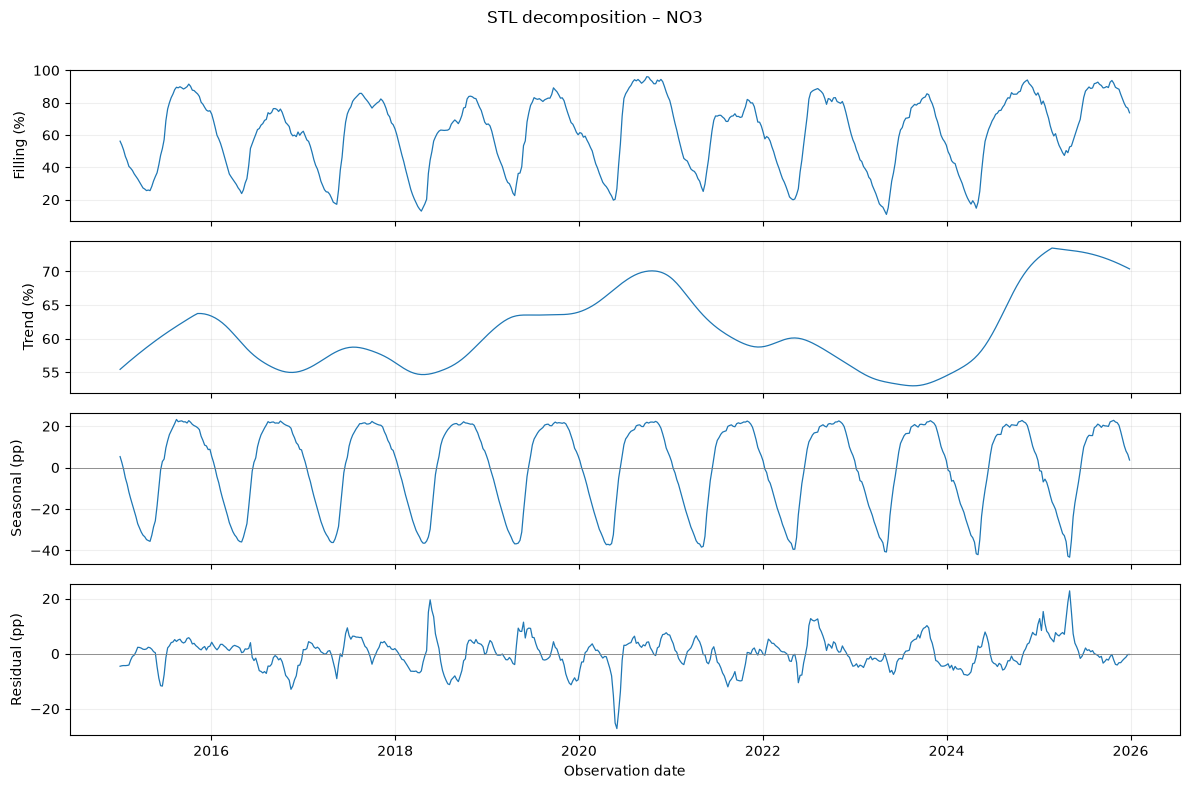

In [4]:
stl_fig = plot_reservoir_stl(filling_no3)
plt.show()

## 7. Reservoir filling: spectrogram

We use the **same weekly NO3 filling series for 2015–2025** as in the STL analysis. A spectrogram shows how the strength of different frequencies changes over time.

### 7.1 Analysis function

The adjustable defaults are **156 weeks per window** (approximately three years) and **78 weeks of overlap** (50%). A Hann window is used, and the mean is removed from each window to emphasise variations.

The horizontal axis shows the centre date of each complete window. The vertical axis uses cycles per 52-week year: **1 corresponds to an approximately annual cycle**. Colours show power relative to the strongest component in decibels (dB). Brighter colours mean stronger variation. Only complete windows are used, so their centre dates do not reach the ends of the series. Source: [SciPy spectrogram](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.spectrogram.html).

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy.signal import spectrogram


def plot_reservoir_spectrogram(filling_fraction, window_length=156, window_overlap=78):
    """Return a spectrogram figure for a regular weekly filling-fraction series."""
    series = filling_fraction.sort_index()
    if not isinstance(series.index, pd.DatetimeIndex) or len(series) < 4:
        raise ValueError("Use a datetime-indexed series with at least four weekly observations.")
    if not (series.index[1:] - series.index[:-1] == pd.Timedelta(days=7)).all():
        raise ValueError("The series must have consecutive, unique weekly observations.")
    values = series.to_numpy(dtype=float)
    if not np.isfinite(values).all():
        raise ValueError("The series contains missing or invalid values.")
    if not isinstance(window_length, (int, np.integer)) or not 4 <= window_length <= len(values):
        raise ValueError("Window length must be an integer between 4 and the series length.")
    if not isinstance(window_overlap, (int, np.integer)) or not 0 <= window_overlap < window_length:
        raise ValueError("Overlap must be an integer from 0 to window length minus 1.")

    # With one observation per week, frequency is in cycles/week and time in weeks.
    frequencies, times, power = spectrogram(
        values, fs=1, window="hann", nperseg=window_length, noverlap=window_overlap,
        detrend="constant", scaling="density", mode="psd",
    )
    if power.max() == 0:
        raise ValueError("The series has no variation to analyse after removing the window means.")
    # Use relative power and a small floor to avoid log10(0).
    power_db = 10 * np.log10(np.maximum(power / power.max(), 1e-8))
    centre_dates = series.index[0] + pd.to_timedelta(times, unit="W")

    fig, ax = plt.subplots(figsize=(12, 4))
    image = ax.pcolormesh(centre_dates, frequencies * 52, power_db,
                         shading="auto", cmap="viridis", vmin=-80, vmax=0)
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.set(title=f"Reservoir filling spectrogram – {series.name or 'weekly series'}",
           xlabel="Window centre date", ylabel="Frequency (cycles per 52-week year)")
    fig.colorbar(image, ax=ax, label="Power relative to maximum (dB)")
    fig.tight_layout()
    return fig

### 7.2 Test the function

We use a weekly signal that changes from a 52-week cycle to a 13-week cycle. The spectrogram should show a shift from 1 to 4 cycles per 52-week year. We also check the effect of window length and overlap.

In [3]:
# A known frequency change halfway through a 20-year test signal.
t = np.arange(20 * 52)
synthetic_spectrum = pd.Series(
    0.5 + 0.15 * np.where(t < len(t) // 2,
                         np.sin(2 * np.pi * t / 52), np.sin(2 * np.pi * t / 13)),
    index=pd.date_range("2000-01-02", periods=len(t), freq="W-SUN"), name="Test signal",
)
test_fig = plot_reservoir_spectrogram(synthetic_spectrum)
mesh = test_fig.axes[0].collections[0]
power_grid = np.asarray(mesh.get_array())
# Read frequency-bin centres from the plotted coordinates to check the axis units too.
frequency_edges = mesh.get_coordinates()[:, 0, 1]
frequency_centres = (frequency_edges[:-1] + frequency_edges[1:]) / 2
peak_frequencies = frequency_centres[power_grid.argmax(axis=0)]
assert np.isclose(peak_frequencies[0], 1)
assert np.isclose(peak_frequencies[-1], 4)
default_shape = power_grid.shape
plt.close(test_fig)

# A shorter window changes frequency resolution; more overlap adds time slices.
test_fig = plot_reservoir_spectrogram(synthetic_spectrum, window_length=104, window_overlap=52)
assert test_fig.axes[0].collections[0].get_array().shape[0] != default_shape[0]
plt.close(test_fig)
test_fig = plot_reservoir_spectrogram(synthetic_spectrum, window_overlap=130)
assert test_fig.axes[0].collections[0].get_array().shape[1] > default_shape[1]
plt.close(test_fig)
print("Tests passed: known frequency change, window length and overlap.")

Tests passed: known frequency change, window length and overlap.


### 7.3 NO3, 2015–2025

Apply the function to the same filling series as STL, using the default window and overlap.

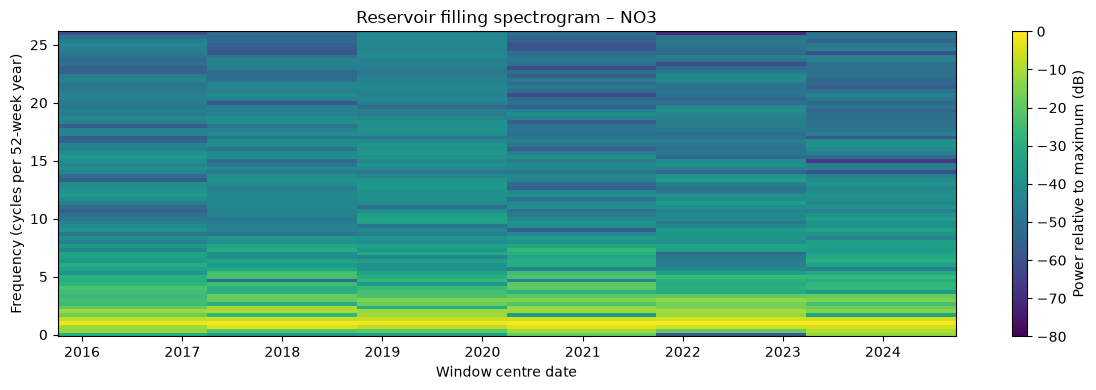

In [4]:
spectrogram_fig = plot_reservoir_spectrogram(filling_no3)
plt.show()